# Phishing URL Detection Using Lexical Feature Engineering
**Objective:** Train a supervised **Random Forest Classifier** to distinguish legitimate web links from phishing URLs based purely on URL structure—without needing to visit or load potentially dangerous web pages.

### Security & Business Context
Attackers frequently disguise malicious links using subdomain spoofing, raw IP addresses, and urgent keywords (`verify`, `login`, `update`). Extracting these lexical indicators programmatically enables email gateways and SOC analysts to block zero-day phishing domains before they appear on public blocklists.

In [1]:
import re
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report
from sklearn.model_selection import train_test_split

rng = np.random.default_rng(42)

# 1. Generate realistic legitimate and phishing URLs
legit_domains = [
    "github.com",
    "microsoft.com",
    "python.org",
    "wikipedia.org",
    "stackoverflow.com",
    "coursera.org",
    "linkedin.com",
    "apple.com",
    "amazon.com",
    "docs.google.com",
]
legit_paths = [
    "/docs/overview",
    "/about/security",
    "/courses/analytics",
    "/articles/guide",
    "/settings/profile",
    "/search?q=python",
    "/blog/release-notes",
    "",
]

brands = ["paypal", "microsoft", "apple", "amazon", "chase", "netflix"]
urls, labels = [], []

for _ in range(150):
  domain = rng.choice(legit_domains)
  path = rng.choice(legit_paths)
  urls.append(f"https://www.{domain}{path}")
  labels.append(0)  # 0 = Legitimate

for _ in range(150):
  brand = rng.choice(brands)
  pattern = rng.integers(0, 4)
  if pattern == 0:
    # Raw IP address instead of domain name
    urls.append(
        f"http://192.168.{rng.integers(1, 255)}.{rng.integers(1, 255)}/login/verify-account.php"
    )
  elif pattern == 1:
    # Hyphen-heavy spoofed domain over HTTP
    urls.append(
        f"http://secure-{brand}-account-update-{rng.integers(10, 99)}.xyz/auth/confirm"
    )
  elif pattern == 2:
    # '@' symbol browser redirect trick
    urls.append(
        f"https://www.{brand}.com@malicious-portal-{rng.integers(1, 99)}.net/signin"
    )
  else:
    # Subdomain spoofing
    urls.append(
        f"http://{brand}.com.verify-user-session.info/login?id={rng.integers(1000, 9999)}"
    )
  labels.append(1)  # 1 = Phishing


# 2. Lexical Feature Engineering Function
def extract_features(url: str) -> dict:
  suspicious_terms = [
      "login",
      "verify",
      "update",
      "secure",
      "account",
      "confirm",
      "signin",
  ]
  return {
      "url_length": len(url),
      "dot_count": url.count("."),
      "hyphen_count": url.count("-"),
      "has_at_symbol": int("@" in url),
      "has_ip_address": int(bool(re.search(r"\d+\.\d+\.\d+\.\d+", url))),
      "uses_https": int(url.startswith("https://")),
      "suspicious_words": sum(term in url.lower() for term in suspicious_terms),
  }


df = pd.DataFrame([extract_features(u) for u in urls])
df["url"] = urls
df["is_phishing"] = labels
df = df.sample(frac=1, random_state=42).reset_index(drop=True)

df[["url", "url_length", "hyphen_count", "uses_https", "is_phishing"]].head(8)

,url,url_length,hyphen_count,uses_https,is_phishing
0,http://amazon.com.verify-user-session.info/log...,56,2,0,1
1,http://192.168.244.244/login/verify-account.php,47,1,0,1
2,https://www.microsoft.com@malicious-portal-31....,56,2,1,1
3,https://www.amazon.com/articles/guide,37,0,1,0
4,http://secure-paypal-account-update-92.xyz/aut...,55,4,0,1
5,http://secure-chase-account-update-97.xyz/auth...,54,4,0,1
6,http://secure-netflix-account-update-12.xyz/au...,56,4,0,1
7,https://www.stackoverflow.com,29,0,1,0


### Model Training & Live URL Testing
We split the dataset into **80% training** and **20% testing** data, fit a **Random Forest Classifier**, and test the trained model on three brand-new URLs it has never seen before.

In [4]:
feature_cols = [
    "url_length",
    "dot_count",
    "hyphen_count",
    "has_at_symbol",
    "has_ip_address",
    "uses_https",
    "suspicious_words",
]

X = df[feature_cols]
y = df["is_phishing"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

clf = RandomForestClassifier(n_estimators=100, random_state=42)
clf.fit(X_train, y_train)

preds = clf.predict(X_test)
print(f"Model Accuracy: {accuracy_score(y_test, preds):.2%}\n")
print(classification_report(y_test, preds, target_names=["Legitimate", "Phishing"]))

# Test on 3 unseen URLs
test_urls = [
    "https://www.github.com/features/security",
    "http://secure-chase-verify-login.xyz/update",
    "https://www.apple.com@fake-auth-check.net/signin",
]
test_features = pd.DataFrame([extract_features(u) for u in test_urls])
test_preds = clf.predict(test_features)

for url, label in zip(test_urls, test_preds):
  verdict = "PHISHING" if label == 1 else "LEGITIMATE"
  print(f"[{verdict:10}] {url}")

Model Accuracy: 100.00%

              precision    recall  f1-score   support

  Legitimate       1.00      1.00      1.00        26
    Phishing       1.00      1.00      1.00        34

    accuracy                           1.00        60
   macro avg       1.00      1.00      1.00        60
weighted avg       1.00      1.00      1.00        60

[LEGITIMATE] https://www.github.com/features/security
[PHISHING  ] http://secure-chase-verify-login.xyz/update
[PHISHING  ] https://www.apple.com@fake-auth-check.net/signin


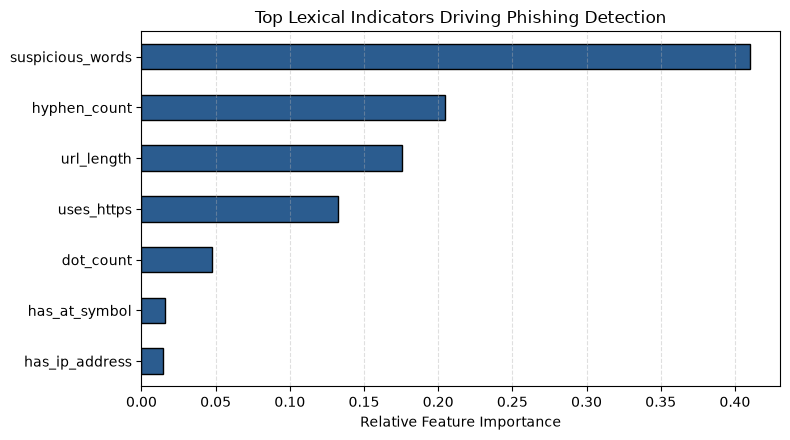

In [3]:
importances = pd.Series(clf.feature_importances_, index=feature_cols).sort_values()

plt.figure(figsize=(8, 4.5))
importances.plot(kind="barh", color="#2b5c8f", edgecolor="black")
plt.title("Top Lexical Indicators Driving Phishing Detection")
plt.xlabel("Relative Feature Importance")
plt.grid(axis="x", linestyle="--", alpha=0.4)
plt.tight_layout()

plt.savefig("phishing_feature_importance.png", dpi=150, bbox_inches="tight")
plt.show()

### Security Takeaways & Defensive Controls
* **Explainable Detection:** Unlike black-box deep learning models, Random Forest feature importance highlights *why* a link was flagged (such as missing HTTPS, suspicious keywords, or abnormal URL length), making alerts easier for SOC analysts to audit.
* **Production Hardening:** In a live environment, lexical URL scoring serves best as a fast first-pass filter alongside SSL certificate age checks and domain reputation APIs.